# BGM weights

Each bidirectional gating module (BGM) gates one branch with a summary of the other:

$$g_\text{time} = \sigma\big(W_{ft}\,\mathrm{GAP}(x_\text{freq}) + b_{ft}\big), \qquad g_\text{freq} = \sigma\big(W_{tf}\,\mathrm{GAP}(x_\text{time}) + b_{tf}\big)$$

$g$ has one value per channel ($C$ = 32, 64, 128 for bgm1-3) and multiplies that channel of the branch. The gated features are
downsampled and concatenated with an ungated (bypass) downsample, then mixed by `expand{k}`.

- **Parameters**: $W$, $b$, and how much weight `expand{k}` puts on the gated half.
- **Gate values**: $g$ for real test windows, by true class (N, AF, and AFL if the fold's test records have flutter).
- **Ablation**: fix the gates and see whether predictions change.

Channel numbers only mean something within one checkpoint (another training can learn them in a different order),
so compare folds with the summary tables, not channel by channel.

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

import pandas as pd
pd.set_option('display.width', 250)
pd.set_option('display.max_columns', 30)

from infrastructure.weights import (parameter_summary, plot_gate_matrices, compare_folds, gate_values,
                                    afl_gate_values, combine, gate_summary, plot_gate_profiles,
                                    plot_gate_distributions, plot_class_separation, path_usage,
                                    plot_path_usage, gate_ablation)

## Choose a model
Any dataset in `visual.DATASETS` (`afdb_acc`, `afdb_spec`, `cpsc`, ...). AFL test records: AFDB fold 3 (07910, 08215),
fold 4 (04936, 128 windows), fold 5 (04908, 1 window); CPSC fold 1 (`data_79_8`), fold 5 (`data_25_13`).

In [2]:
dataset, fold = 'afdb_acc', 4

## 1. Parameters
`sigmoid(b) mean`: the gate for an all-zero input. `expand weight share on BGM half`: share of the next conv's weight norm
on the gated half of its input (0.5 = equal to the bypass).

In [3]:
parameter_summary(dataset, fold)

from    C  |W| mean   W std  W frobenius  b mean   b std  sigmoid(b) mean  expand weight share on BGM half
bgm  gate on                                                                                                            
bgm1 time     freq   32    0.0551  0.0732       2.6172 -0.0450  0.0534           0.4888                           0.5232
     freq     time   32    0.0152  0.0241       0.7719 -0.0025  0.0431           0.4994                           0.5056
bgm2 time     freq   64    0.0119  0.0311       1.9931 -0.0212  0.0542           0.4947                           0.5849
     freq     time   64    0.0067  0.0186       1.1876 -0.0046  0.0314           0.4988                           0.6476
bgm3 time     freq  128    0.0034  0.0128       1.6348 -0.0095  0.0359           0.4976                           0.6700
     freq     time  128    0.0106  0.0312       4.0516 -0.0124  0.0372           0.4969                           0.7469

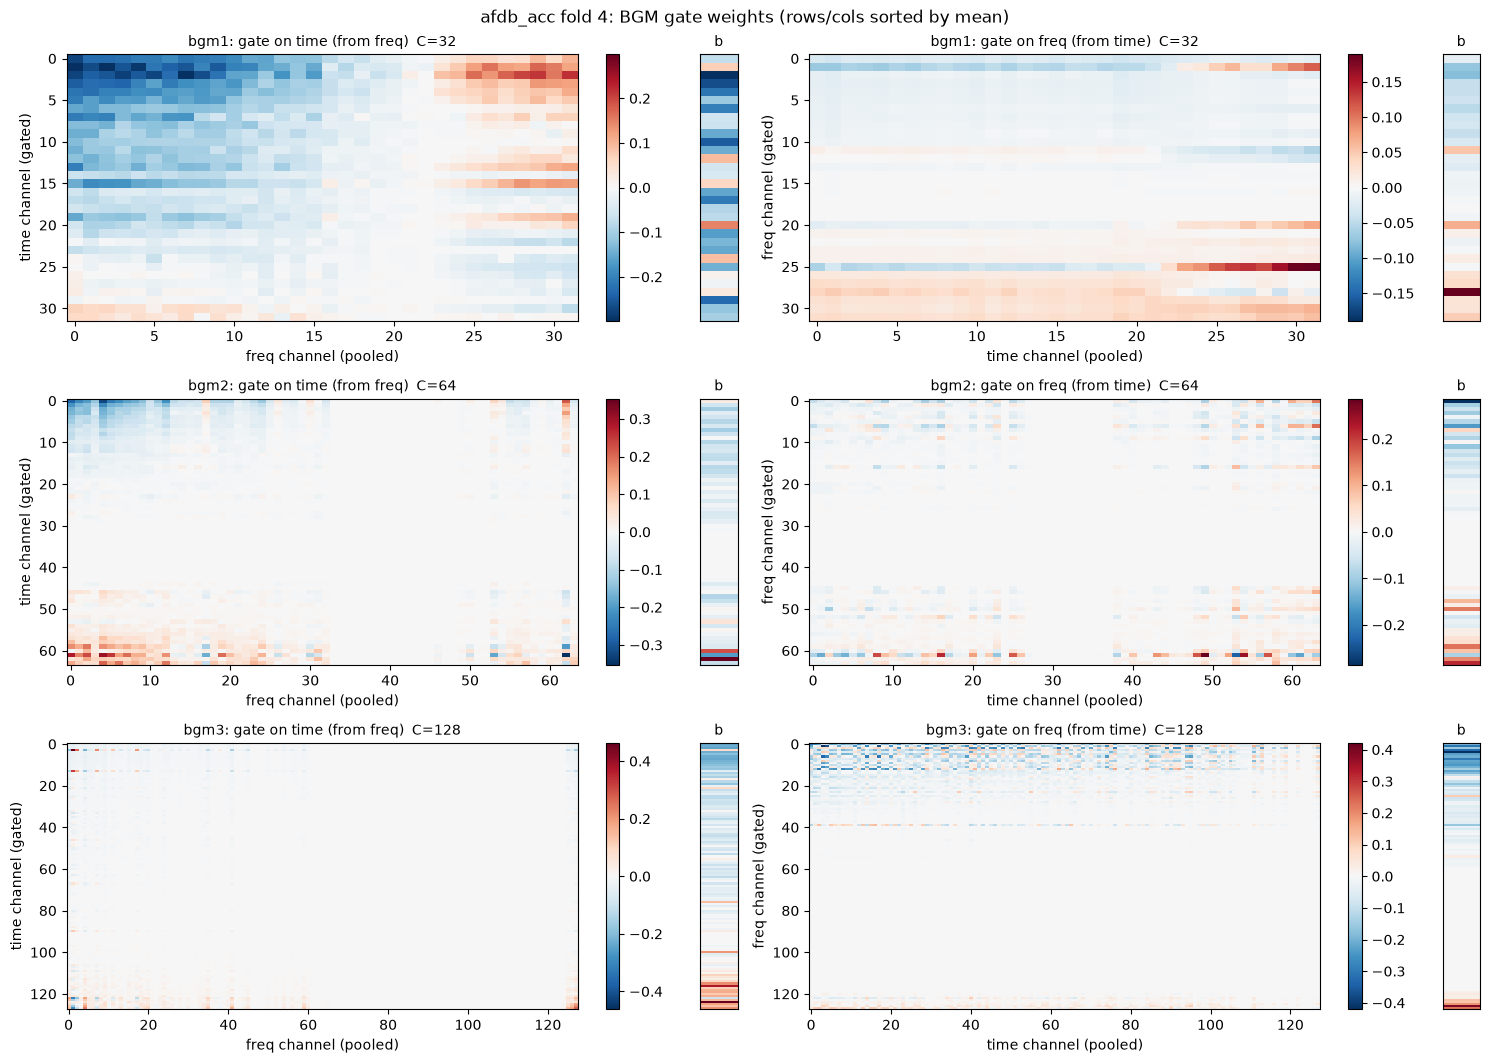

In [4]:
plot_gate_matrices(dataset, fold)

In [5]:
# the same summary across folds
compare_folds(dataset)

from    C  |W| mean   W std  W frobenius  b mean   b std  sigmoid(b) mean  expand weight share on BGM half
fold bgm  gate on                                                                                                            
1    bgm1 time     freq   32    0.0496  0.0662       2.2714 -0.0379  0.0501           0.4905                           0.5250
          freq     time   32    0.0140  0.0229       0.7338 -0.0059  0.0317           0.4985                           0.5901
     bgm2 time     freq   64    0.0068  0.0179       1.1434 -0.0099  0.0332           0.4975                           0.5615
          freq     time   64    0.0085  0.0247       1.5910 -0.0057  0.0284           0.4986                           0.6134
     bgm3 time     freq  128    0.0024  0.0122       1.5646 -0.0103  0.0508           0.4974                           0.6319
          freq     time  128    0.0096  0.0311       4.0278 -0.0144  0.0371           0.4964                           0.9066
2    bgm1 time     freq   32    0.0447  0.0614       2.1302 -0.0412  0.0440           0.4897                           0.5346
          freq     time   32    0.0114  0.0220       0.7304 -0.0061  0.0354           0.4985                           0.5861
     bgm2 time     freq   64    0.0084  0.0230       1.4735 -0.0170  0.0297           0.4958                           0.5812
          freq     time   64    0.0065  0.0237       1.5241 -0.0063  0.0285           0.4984                           0.6067
     bgm3 time     freq  128    0.0037  0.0146       1.8820 -0.0104  0.0404           0.4974                           0.6396
          freq     time  128    0.0097  0.0295       3.8292 -0.0151  0.0359           0.4962                           0.7567
3    bgm1 time     freq   32    0.0488  0.0685       2.2585 -0.0456  0.0474           0.4886                           0.5264
          freq     time   32    0.0109  0.0174       0.5629 -0.0031  0.0280           0.4992                           0.5830
     bgm2 time     freq   64    0.0045  0.0139       0.8878 -0.0048  0.0314           0.4988                           0.5638
          freq     time   64    0.0025  0.0072       0.4637  0.0014  0.0157           0.5004                           0.5480
     bgm3 time     freq  128    0.0016  0.0091       1.1690 -0.0054  0.0307           0.4987                           0.6297
          freq     time  128    0.0046  0.0234       3.0038 -0.0076  0.0216           0.4981                           0.7743
4    bgm1 time     freq   32    0.0551  0.0732       2.6172 -0.0450  0.0534           0.4888                           0.5232
          freq     time   32    0.0152  0.0241       0.7719 -0.0025  0.0431           0.4994                           0.5056
     bgm2 time     freq   64    0.0119  0.0311       1.9931 -0.0212  0.0542           0.4947                           0.5849
          freq     time   64    0.0067  0.0186       1.1876 -0.0046  0.0314           0.4988                           0.6476
     bgm3 time     freq  128    0.0034  0.0128       1.6348 -0.0095  0.0359           0.4976                           0.6700
          freq     time  128    0.0106  0.0312       4.0516 -0.0124  0.0372           0.4969                           0.7469
5    bgm1 time     freq   32    0.0769  0.0898       2.8782 -0.0219  0.0994           0.4945                           0.4997
          freq     time   32    0.0738  0.0871       2.7875  0.0233  0.1020           0.5058                           0.5017
     bgm2 time     freq   64    0.0427  0.0505       3.2377 -0.0062  0.0542           0.4984                           0.4963
          freq     time   64    0.0463  0.0544       3.4892 -0.0104  0.0516           0.4974                           0.5016
     bgm3 time     freq  128    0.0084  0.0109       1.4057 -0.0004  0.0202           0.4999                           0.5039
          freq     time  128    0.0336  0.0402       5.1560 -0.0050  0.0437           0.4987                     

## 2. Gate values on test windows
A uniform sample of the fold's test windows (`n_per_class` of each true class), checked against `test_predictions.csv`,
plus the AFL windows of the fold's test records (`test_patients_only=False` uses every AFL record, including ones whose
AF/N windows were in training).

In [6]:
res = gate_values(dataset, fold, n_per_class=200)
afl = afl_gate_values(dataset, fold)
res = combine(res, afl)
res['table']['true'].value_counts()

true
N      200
AF     200
AFL    128
Name: count, dtype: int64

`window spread` near 0 means a gate gives almost the same value whatever the input, i.e. it is a fixed per-channel scale.
Compare `max |d|` (effect size) with `max |mean AF - mean N|` (difference in gate value): a large $d$ can come from a tiny,
consistent difference.

In [7]:
gate_summary(res)

C   mean  channel spread  window spread   <0.1  >0.9  mean N  mean AF  mean AFL  max |d| AF-N  channels |d|>0.8  max |mean AF - mean N|
bgm  gate on                                                                                                                                           
bgm1 time      32  0.408           0.059          0.009  0.000   0.0   0.407    0.410     0.405         1.321                 1                   0.007
     freq      32  0.499           0.036          0.002  0.000   0.0   0.499    0.499     0.499         1.116                30                   0.007
bgm2 time      64  0.488           0.054          0.004  0.000   0.0   0.488    0.489     0.488         1.537                25                   0.015
     freq      64  0.499           0.021          0.004  0.000   0.0   0.499    0.499     0.499         1.615                43                   0.053
bgm3 time     128  0.496           0.030          0.003  0.000   0.0   0.495    0.496     0.496         1.776                46                   0.027
     freq     128  0.467           0.083          0.008  0.001   0.0   0.467    0.468     0.464         2.794                54                   0.102

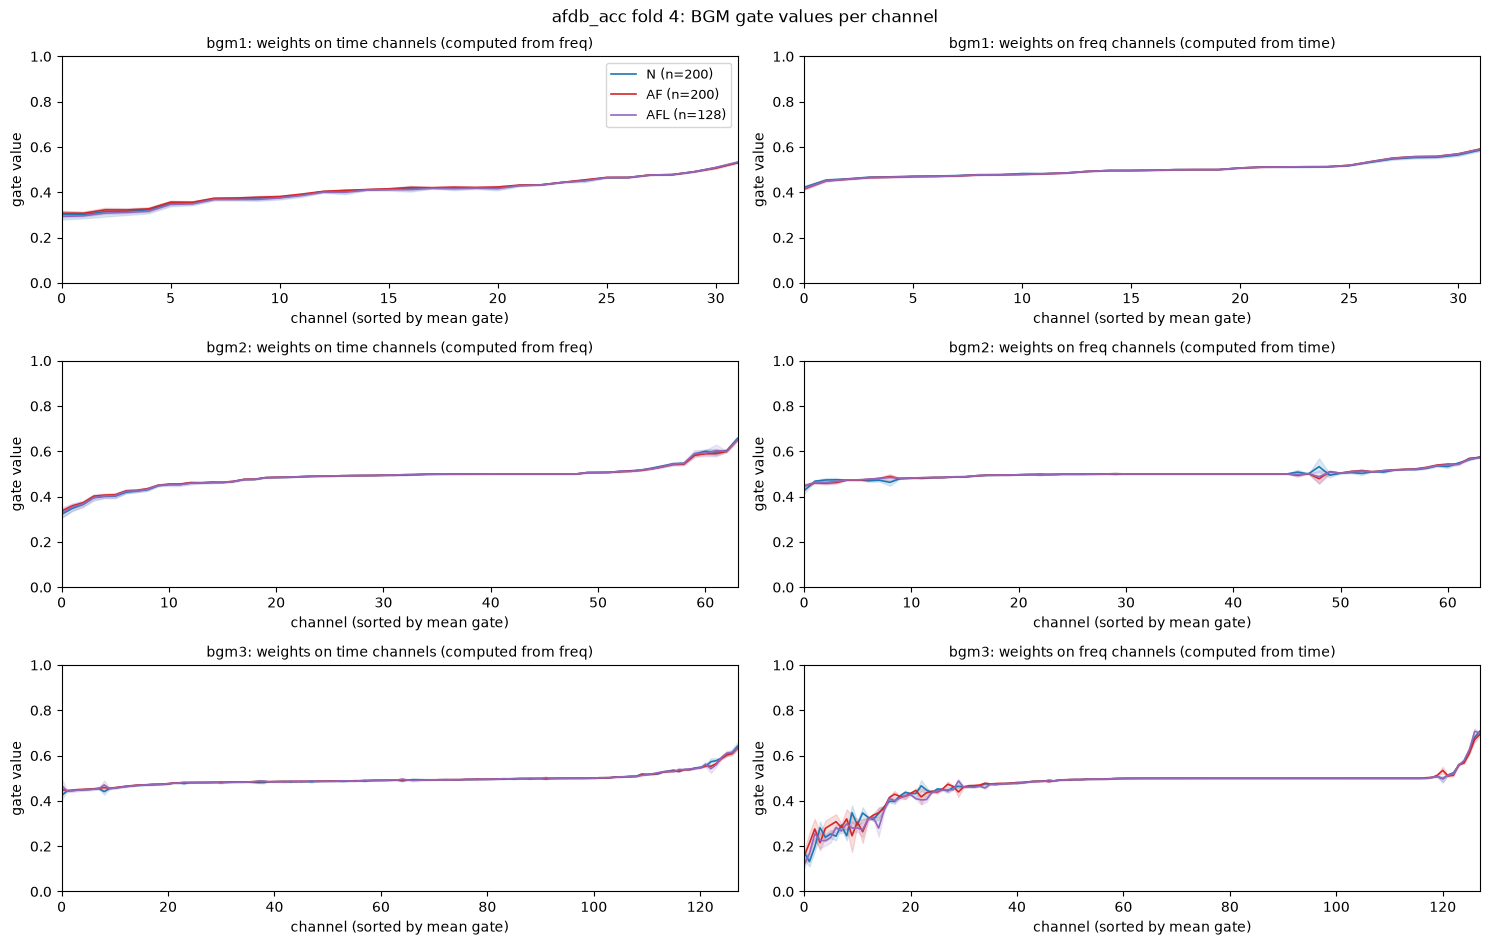

In [8]:
plot_gate_profiles(res)

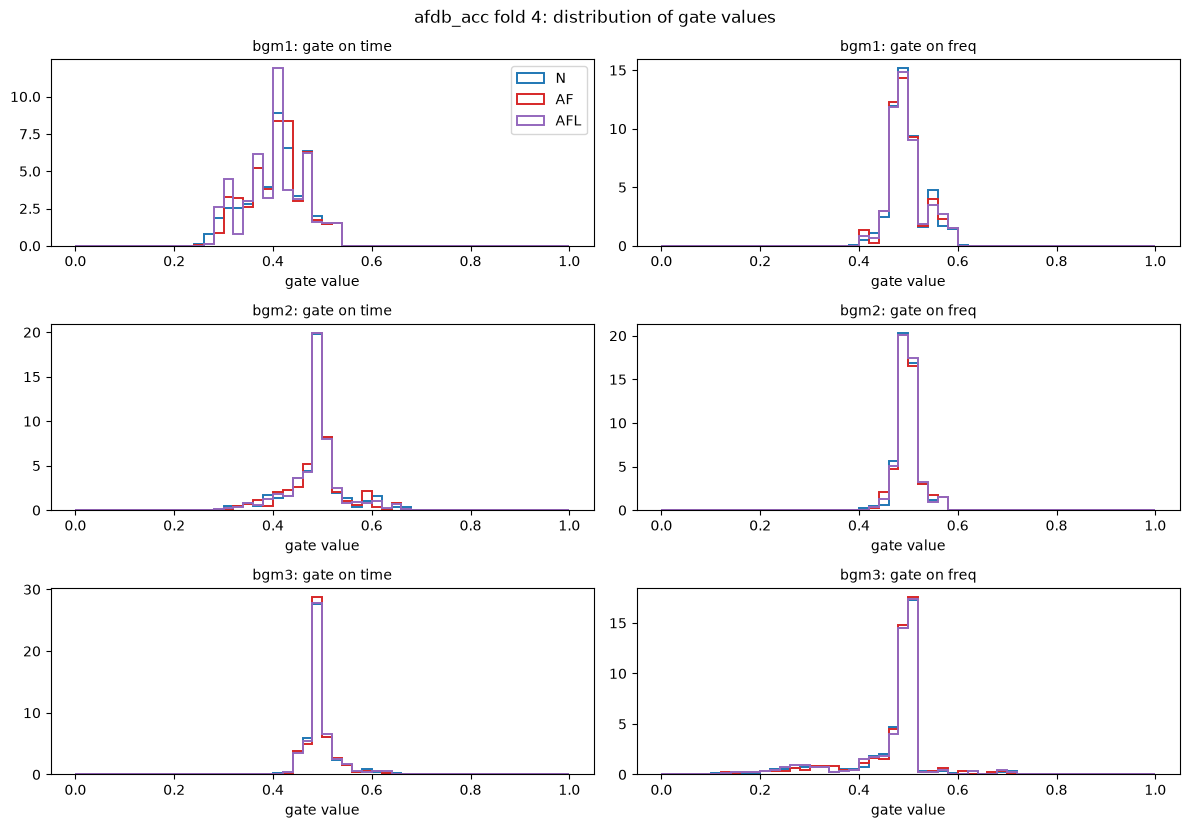

In [9]:
plot_gate_distributions(res)

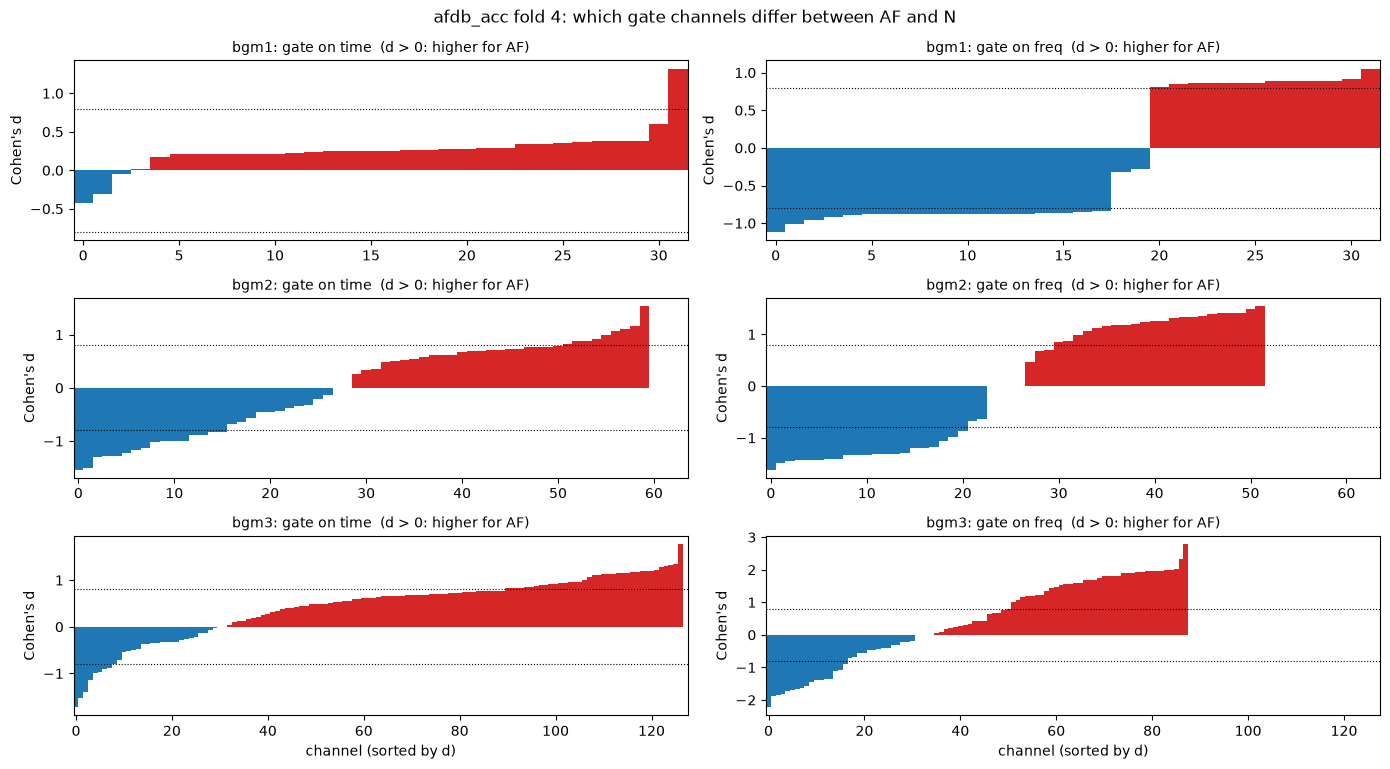

,bgm,gate on,channel,d,mean AF,mean N
0,bgm1,time,20,1.321,0.465,0.465
1,bgm1,time,10,0.606,0.466,0.464
2,bgm1,time,25,-0.426,0.490,0.491
3,bgm1,time,18,0.386,0.421,0.419
4,bgm1,time,27,0.386,0.415,0.413
5,bgm1,time,13,0.382,0.477,0.476
6,bgm1,time,2,0.369,0.381,0.377
7,bgm1,time,30,0.355,0.432,0.430
8,bgm1,time,15,0.347,0.455,0.452
9,bgm1,time,24,0.337,0.391,0.388


In [10]:
plot_class_separation(res, 'AF', 'N').head(10)

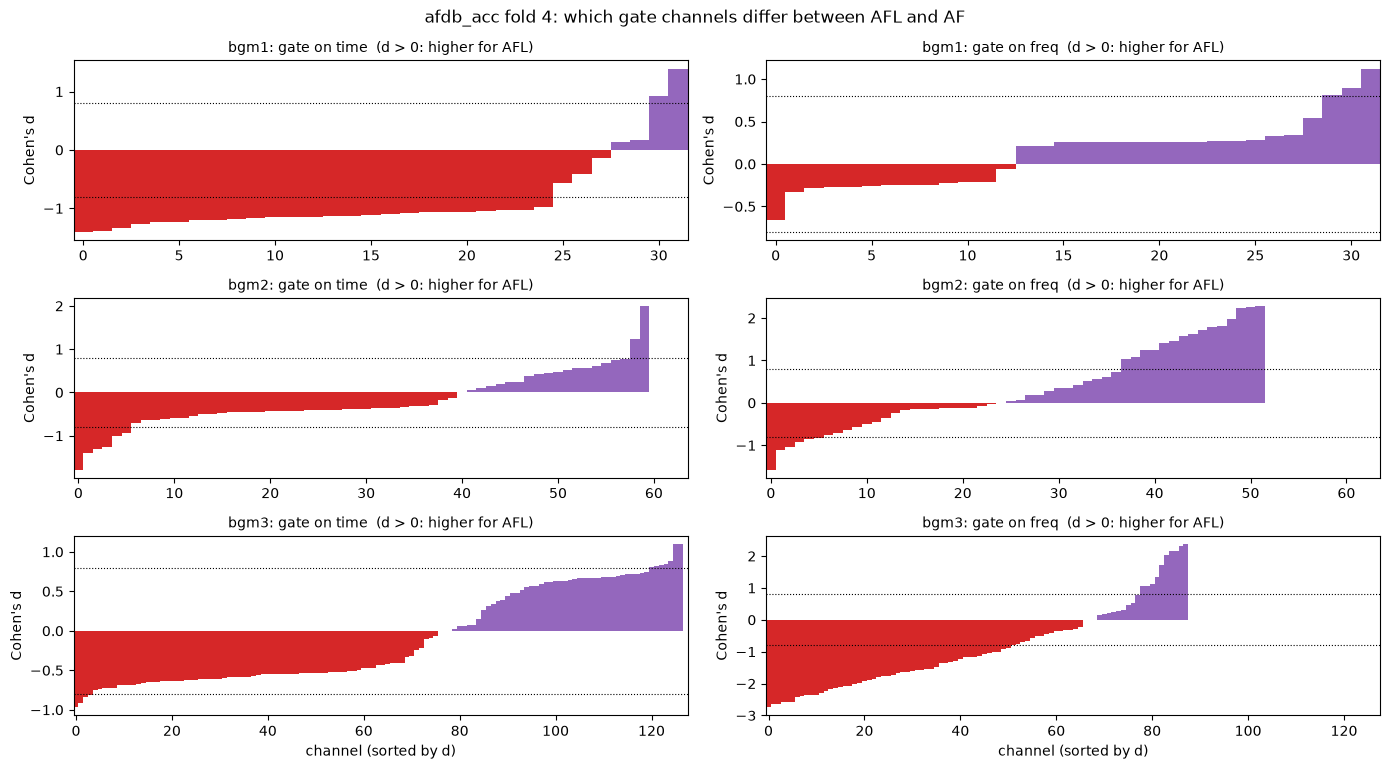

,bgm,gate on,channel,d,mean AFL,mean AF
0,bgm1,time,31,-1.404,0.409,0.412
1,bgm1,time,6,1.395,0.533,0.530
2,bgm1,time,14,-1.385,0.417,0.420
3,bgm1,time,8,-1.343,0.400,0.404
4,bgm1,time,1,-1.264,0.368,0.374
5,bgm1,time,27,-1.240,0.411,0.415
6,bgm1,time,28,-1.231,0.368,0.373
7,bgm1,time,30,-1.204,0.429,0.432
8,bgm1,time,16,-1.197,0.349,0.356
9,bgm1,time,18,-1.183,0.418,0.421


In [11]:
# flutter vs AF (needs AFL windows in res)
if 'AFL' in set(res['table']['true']):
    display(plot_class_separation(res, 'AFL', 'AF').head(10))

## 3. Gated path vs bypass
Share of each `expand` conv's output that comes from the BGM half of its input, measured on the windows above.

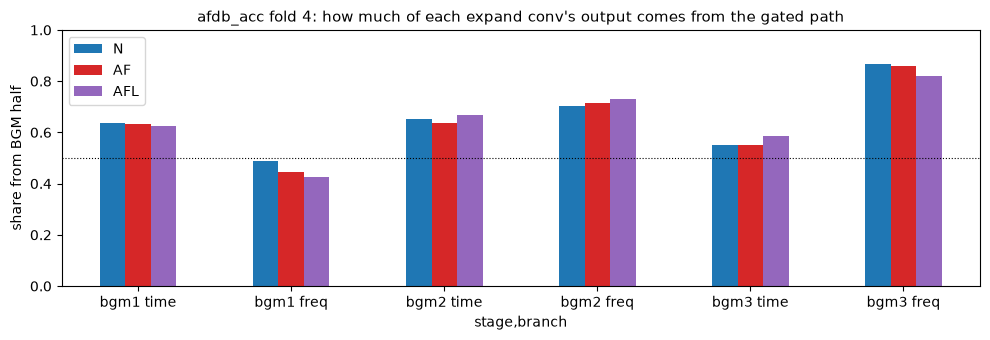

all      N     AF    AFL
stage           branch                            
bgm1 -> expand1 time    0.632  0.636  0.631  0.626
                freq    0.457  0.487  0.445  0.426
bgm2 -> expand2 time    0.651  0.654  0.636  0.669
                freq    0.714  0.703  0.716  0.729
bgm3 -> expand3 time    0.560  0.551  0.552  0.584
                freq    0.852  0.866  0.859  0.821

In [12]:
plot_path_usage(res)

## 4. Do the gate values matter?
Replace each gate with its per-channel mean (no input dependence), or give each window the other class's mean gate.
If accuracy and P(AF) hardly change, the BGMs act as fixed channel scales (absorbed by the following BatchNorm),
not as input-dependent cross-modal gates.

In [13]:
gate_ablation(res)

,accuracy,mean |dP(AF)|,flips
setting,,,
as trained,0.915,0.0000,0
channel mean,0.925,0.0450,22
other class,0.935,0.0481,22


In [14]:
# the same check for every fold (slow: about 30 s per fold)
pd.concat({f: gate_ablation(gate_values(dataset, f, n_per_class=200)) for f in range(1, 6)}, names=['fold'])

accuracy  mean |dP(AF)|  flips
fold setting                                     
1    as trained      0.9975         0.0000      0
     channel mean    1.0000         0.0040      1
     other class     0.9975         0.0078      0
2    as trained      0.9600         0.0000      0
     channel mean    0.9600         0.0171      4
     other class     0.9600         0.0201      4
3    as trained      0.9600         0.0000      0
     channel mean    0.9675         0.0204      5
     other class     0.9650         0.0191      6
4    as trained      0.9150         0.0000      0
     channel mean    0.9200         0.0592     22
     other class     0.9350         0.0632     22
5    as trained      0.9150         0.0000      0
     channel mean    0.8900         0.0284     12
     other class     0.8550         0.0619     24